# M5: City segments and KPIs

This is the Path B follow-up to the M4 notebook. It looks at where connection-seeking posts are concentrated, when they are posted, and which age groups post which kind of intent. The window is still Aug 2025 to Aug 2026.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("../data/processed/posts_clean.csv", low_memory=False)
df["date_manila"] = pd.to_datetime(df["date_manila"])
window = df[df["date_manila"] >= "2025-08-01"].copy()

pop = pd.read_csv("../data/reference/metro_manila_population.csv")
pop_lookup = dict(zip(pop["city"], pop["population"]))

window["late_night"] = window["hour_manila"].isin([22, 23, 0, 1])
os.makedirs("../output/tables", exist_ok=True)

print(len(window), "posts from", window["date_manila"].min().date(), "to", window["date_manila"].max().date())


197082 posts from 2025-08-01 to 2026-08-03


## What I compare

| Segment | Why it matters | Metric |
|---|---|---|
| City | Where the demand is | posts per 100k, late-night share, intent shares |
| Age band | Who is posting | intent mix |
| Month | Whether the pattern is stable | posts per day, late-night share |

I use four KPIs: posts per 100,000 residents, late-night share (10 PM to 2 AM), platonic share, and sexual share. The first two are for reach and scheduling; the last two describe what kind of demand is there.


In [2]:
city_posts = window[window["city"].isin(pop_lookup)].pivot_table(
    index="city", columns="category", values="post_id", aggfunc="count"
).fillna(0)

kpi = pd.DataFrame(index=city_posts.index)
kpi["posts"] = city_posts.sum(axis=1)
kpi["population"] = kpi.index.map(pop_lookup)
kpi["posts_per_100k"] = kpi["posts"] / kpi["population"] * 100_000
kpi["platonic_share"] = city_posts["platonic"] / kpi["posts"]
kpi["romantic_share"] = city_posts["romantic"] / kpi["posts"]
kpi["sexual_share"] = city_posts["sexual"] / kpi["posts"]

late = window[window["city"].isin(pop_lookup)].groupby("city")["late_night"].mean()
kpi["late_night_share"] = late
kpi = kpi.sort_values("posts_per_100k", ascending=False)

show = kpi.head(10).copy()
for col in ["late_night_share", "platonic_share", "romantic_share", "sexual_share"]:
    show[col] = (show[col] * 100).round(1)
show.round(1)


,posts,population,posts_per_100k,platonic_share,romantic_share,sexual_share,late_night_share
city,,,,,,,
Makati,8965.0,309770,2894.1,16.0,4.3,13.8,19.6
Manila,14199.0,1902590,746.3,14.1,4.2,21.5,24.9
Quezon City,18287.0,3084270,592.9,11.0,4.2,23.9,22.2
Mandaluyong,2244.0,465902,481.6,7.6,2.3,18.8,24.2
Taguig,5918.0,1308085,452.4,16.9,4.1,21.2,20.8
Pasay,1942.0,453186,428.5,7.2,2.6,36.1,24.9
Pasig,3238.0,853050,379.6,9.3,3.9,19.3,26.5
Marikina,1645.0,471323,349.0,12.5,3.5,12.8,22.5
San Juan,416.0,134312,309.7,11.3,4.6,16.6,23.6


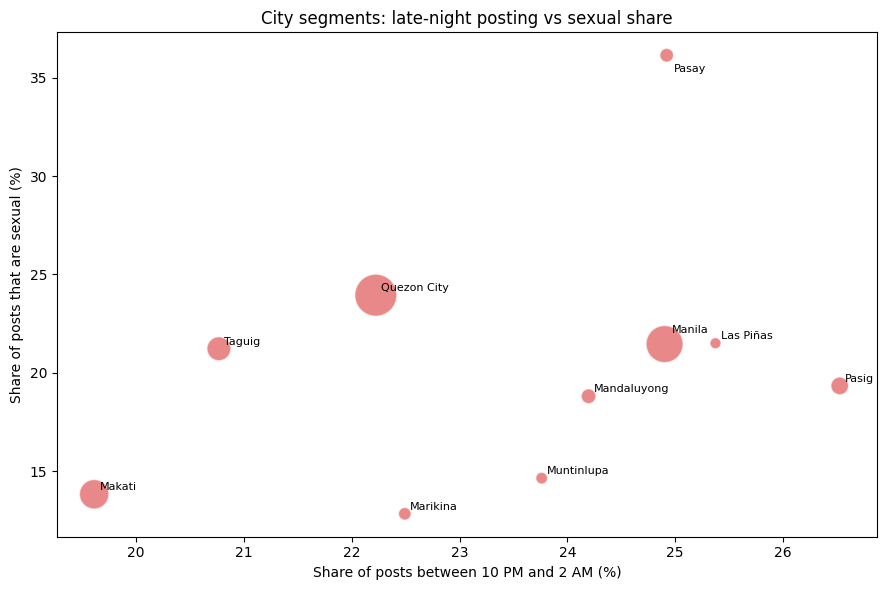

In [3]:
top = kpi[kpi["posts"] >= 1000]
offsets = {"Manila": (5, 8), "Pasay": (5, -12)}

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    top["late_night_share"] * 100,
    top["sexual_share"] * 100,
    s=top["posts"] / 20,
    alpha=0.55,
    color="tab:red",
    edgecolor="white",
)
for city, row in top.iterrows():
    ax.annotate(
        city,
        (row["late_night_share"] * 100, row["sexual_share"] * 100),
        xytext=offsets.get(city, (4, 3)),
        textcoords="offset points",
        fontsize=8,
    )
ax.set_title("City segments: late-night posting vs sexual share")
ax.set_xlabel("Share of posts between 10 PM and 2 AM (%)")
ax.set_ylabel("Share of posts that are sexual (%)")
plt.tight_layout()
plt.savefig("../output/figures/fig6_city_segments.png", dpi=120)
plt.show()


## Age and intent

The age bands below use only posts with a clear intent tag (platonic, romantic, sexual). The general r4r category is left out so the shares add up to 100%.

In [4]:
age_order = ["18-24", "25-29", "30-34", "35+"]
window["age_band"] = pd.cut(window["seeker_age"], bins=[17, 24, 29, 34, 120], labels=age_order)
age_posts = window[(window["category"] != "all") & window["age_band"].notna()].copy()
age_posts["age_band"] = age_posts["age_band"].astype(str)

age_intent = pd.crosstab(age_posts["age_band"], age_posts["category"], normalize="index")
age_intent = age_intent[["platonic", "romantic", "sexual"]]
age_intent.round(3)

category,platonic,romantic,sexual
age_band,,,
18-24,0.602,0.062,0.336
25-29,0.651,0.089,0.260
30-34,0.539,0.115,0.347
35+,0.295,0.135,0.569


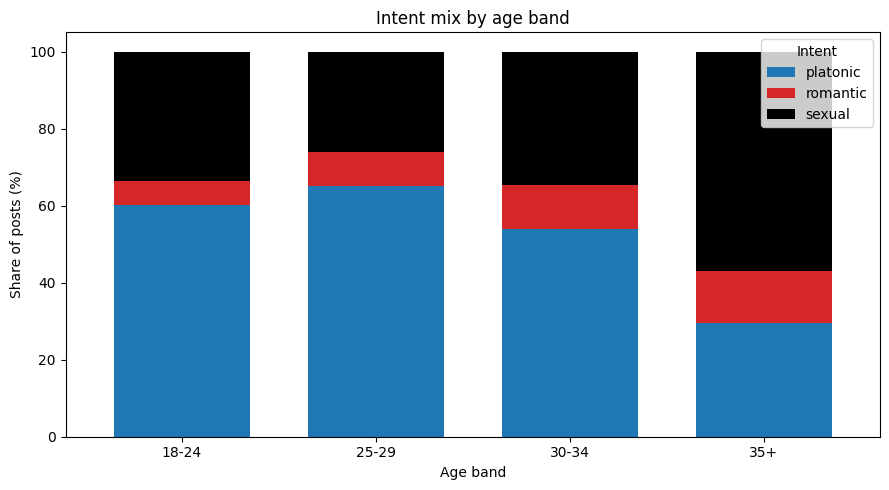

In [5]:
colors = {"platonic": "tab:blue", "romantic": "tab:red", "sexual": "black"}

ax = age_intent.mul(100).plot(
    kind="bar", stacked=True, figsize=(9, 5), width=0.7,
    color=[colors[c] for c in age_intent.columns],
)
ax.set_title("Intent mix by age band")
ax.set_xlabel("Age band")
ax.set_ylabel("Share of posts (%)")
ax.legend(title="Intent", loc="upper right")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../output/figures/fig7_age_intent.png", dpi=120)
plt.show()

## Monthly trend

A quick check that the late-night pattern is not just one busy month.

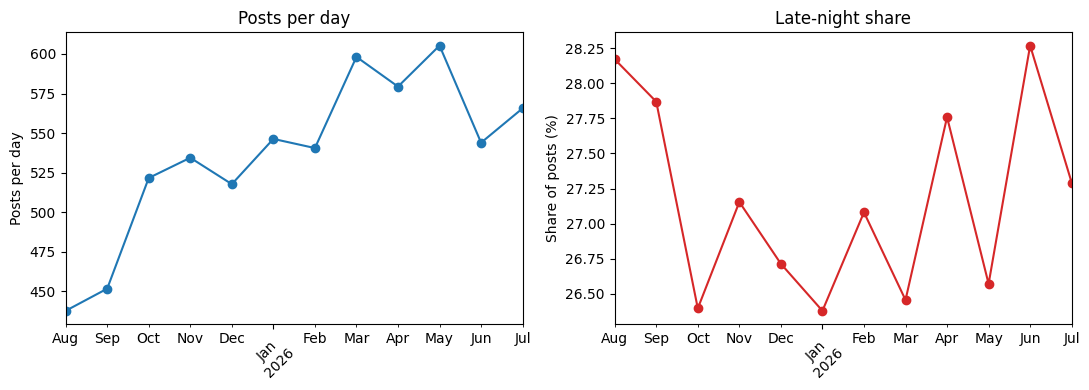

In [6]:
window["month_start"] = window["date_manila"].dt.to_period("M").dt.to_timestamp()
monthly = window.groupby("month_start").agg(
    posts=("post_id", "size"),
    late_night_share=("late_night", "mean"),
)
monthly = monthly[monthly.index < "2026-08-01"].copy()
monthly["posts_per_day"] = monthly["posts"] / monthly.index.days_in_month

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
monthly["posts_per_day"].plot(ax=axes[0], marker="o", color="tab:blue")
axes[0].set_title("Posts per day")
axes[0].set_xlabel("")
axes[0].set_ylabel("Posts per day")

monthly["late_night_share"].mul(100).plot(ax=axes[1], marker="o", color="tab:red")
axes[1].set_title("Late-night share")
axes[1].set_xlabel("")
axes[1].set_ylabel("Share of posts (%)")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("../output/figures/fig8_monthly_kpis.png", dpi=120)
plt.show()


In [7]:
kpi.round(3).to_csv("../output/tables/m5_city_kpis.csv")
age_intent.round(3).to_csv("../output/tables/m5_age_intent.csv")
monthly.round(3).to_csv("../output/tables/m5_monthly.csv")
print("saved", len(kpi), "city rows and", len(monthly), "months")

saved 16 city rows and 12 months


## KPI definitions

| KPI | Calculation | Why it matters |
|---|---|---|
| Posts per 100,000 residents | city posts / city population x 100,000 | compares demand across different city sizes |
| Late-night share | posts between 10 PM and 2 AM / all posts in the city | shows when outreach or events should be active |
| Platonic share | platonic posts / all posts in the city | measures how much of the demand is friendship-oriented |
| Sexual share | sexual posts / all posts in the city | measures how much of the demand is sexual-health related |


## What this means

Makati has the highest per-capita volume by a wide margin: about 2,894 posts per 100,000 residents, compared with 746 in Manila and 593 in Quezon City. Its platonic share (16.0%) is also above Manila and Quezon City, but its sexual share (13.8%) is the lowest among the four largest cities by volume. That makes Makati a good first test for general social spaces.

Pasay has the highest sexual share (36.1%) and a late-night share of 24.9%, even though its per-capita volume is lower. For sexual-health outreach, Pasay is the clearer target. Muntinlupa and Taguig have the highest platonic shares (18.5% and 16.9%), so they are better fits for friendship-oriented programming. San Juan has a high per-capita rate but only 416 posts, so I would not lean on it.

Age shows a clear split in intent. Under-30 posters are mostly platonic (60% for 18-24 and 65% for 25-29), while 35+ is mostly sexual (57%). Late-night share stays between 26% and 28% across the 12 full months, so the timing KPI is stable. August 2026 is only three days, so I left it out of the trend.

## Limits

- Only about 36% of posts name a city.
- City matching keeps the first city mentioned when a post names more than one.
- Reddit posters are not a sample of city residents.
- These are descriptive rates, not evidence that one place causes a behavior.
